# What the stats say a player is worth

The market price is the target, not an input. For every player-season from 2022-23 through 2025-26 with at least 900 minutes, a Transfermarkt id, and a season-end fee, we predict log(fee) from age, minutes, league, role, playing style, and the per-90 stats. Goals and assists are included here. They were left out of the style clusters because a goal is a result, but a result is exactly what a fee pays for.

Each row is scored by a model that never saw that player. The gap is predicted fee divided by actual fee. A gap of 2 means the stats imply twice the market price.

## Two ways to miss

Ridge is the plain model: a straight line in the scaled features, with the penalty chosen by cross-validation. Gradient boosting is the flexible one. It can bend.

We score both twice. In the grouped test, the same player is never in both the training fold and the test fold, so the model cannot memorize him from another season. In the time split, the model trains on 2022-23 through 2024-25 and is tested on 2025-26, a season it has never seen.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.value_model import (
    build_modeling_frame,
    choose_model,
    evaluate_models,
    out_of_fold_predictions,
    ridge_effects,
    top_undervalued,
    STRENGTH_COLUMNS,
    weak_club_count,
)

LEAGUES = {
    "ENG-Premier League": "Premier League",
    "ESP-La Liga": "La Liga",
    "GER-Bundesliga": "Bundesliga",
    "ITA-Serie A": "Serie A",
    "FRA-Ligue 1": "Ligue 1",
}
ROLE_ORDER = ["CB", "FB", "CM", "AM_W", "ST"]
ROLE_TITLE = {
    "CB": "Centre-backs",
    "FB": "Fullbacks",
    "CM": "Central midfielders",
    "AM_W": "Attacking midfielders and wingers",
    "ST": "Strikers",
}

def money(value):
    return f"€{value / 1e6:.1f}m"

modeling = build_modeling_frame()
before_frame = modeling.drop(columns=list(STRENGTH_COLUMNS))
before_metrics = evaluate_models(before_frame)
after_metrics = evaluate_models(modeling)
winner, reason = choose_model(after_metrics)

def _show(metrics, version):
    shown = metrics.copy()
    shown.insert(0, "version", version)
    shown["model"] = shown["model"].map({"ridge": "Ridge", "hist_gradient_boosting": "Gradient boosting"})
    return shown

comparison = pd.concat([_show(before_metrics, "Before"), _show(after_metrics, "After")], ignore_index=True)
comparison = comparison.rename(
    columns={
        "version": "Version",
        "model": "Model",
        "split": "Test",
        "r2": "R²",
        "mae_log": "MAE (log fee)",
        "median_abs_pct_error": "Median abs % error",
    }
)
comparison["R²"] = comparison["R²"].round(3)
comparison["MAE (log fee)"] = comparison["MAE (log fee)"].round(3)
comparison["Median abs % error"] = comparison["Median abs % error"].round(1)
display(comparison)
print(reason)
print(f"{len(modeling)} player-seasons in the fit.")

before_scores = out_of_fold_predictions(before_frame, "ridge", save=False)
predictions = out_of_fold_predictions(modeling, winner)
before_weak = weak_club_count(before_scores)
after_weak = weak_club_count(predictions)
print(f"Bottom-third clubs in the top 50 (age ≤27, fee ≥ €2m): {before_weak} before, {after_weak} after.")


Feature list: goals_per90, non_penalty_goals_per90, assists_per90, shots_per90, shots_on_target_per90, crosses_per90, tackles_won_per90, interceptions_per90, fouls_committed_per90, fouls_drawn_per90, offsides_per90, shot_accuracy, goals_per_shot


,Version,Model,Test,R²,MAE (log fee),Median abs % error
0,Before,Ridge,GroupKFold,0.609,0.600,48.7
1,Before,Ridge,time split 2025-26,0.619,0.586,45.6
2,Before,Gradient boosting,GroupKFold,0.595,0.611,49.1
3,Before,Gradient boosting,time split 2025-26,0.620,0.586,45.3
4,After,Ridge,GroupKFold,0.826,0.386,30.5
5,After,Ridge,time split 2025-26,0.820,0.390,33.2
6,After,Gradient boosting,GroupKFold,0.850,0.359,28.2
7,After,Gradient boosting,time split 2025-26,0.828,0.374,29.9


We keep hist_gradient_boosting. On the 2025-26 season it never trained on, its median absolute error is 29.9% of the fee, against 33.2% for ridge.
5657 player-seasons in the fit.


Bottom-third clubs in the top 50 (age ≤27, fee ≥ €2m): 33 before, 12 after.


## Fix: the model was mistaking small clubs for undervalued players

The first lists were full of regulars at Levante, Hamburger SV, Lecce, Verona, and the newly promoted clubs. The model had no idea how strong the team was, so a full season at a weak club looked like a bargain.

Team strength is now the average log fee of the other players at that club that season. The player's own fee is left out. A second feature is the club's share of its league's total squad value, and minutes are multiplied by team strength so a heavy workload at a strong club is not the same thing as a heavy workload at a weak one.

Of the 50 most undervalued players aged 27 or under and priced at €2m or more, 33 played for a bottom-third squad before this fix and 12 after it.

## Predicted fee against the real fee

Both axes are on a log scale, so a player at €2m and a player at €80m can share the chart. The line is a perfect prediction. Points above the line are the ones whose stats imply a higher fee than the market. Tottenham's 2025-26 regulars are ringed.

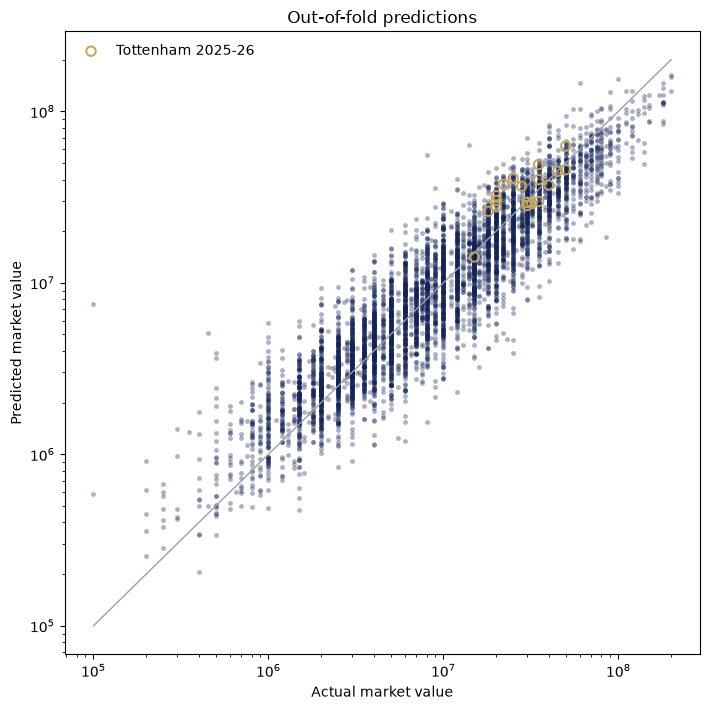

In [2]:
fig, ax = plt.subplots(figsize=(7.2, 7.2))
ax.scatter(
    predictions["actual_value"],
    predictions["predicted_value"],
    s=12,
    alpha=0.35,
    color="#132257",
    linewidths=0,
)
spurs = predictions.loc[(predictions["team"] == "Tottenham") & (predictions["season"] == 2526)]
ax.scatter(
    spurs["actual_value"],
    spurs["predicted_value"],
    s=46,
    facecolors="none",
    edgecolors="#C4A35A",
    linewidths=1.4,
    zorder=3,
    label="Tottenham 2025-26",
)
span = [
    predictions[["actual_value", "predicted_value"]].min().min(),
    predictions[["actual_value", "predicted_value"]].max().max(),
]
ax.plot(span, span, color="#9aa0a6", linewidth=1)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Actual market value")
ax.set_ylabel("Predicted market value")
ax.set_title("Out-of-fold predictions")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


## What the straight-line model is paying for

These are Ridge's ten largest coefficients, fit on 2022-23 through 2024-25 only. They are associations, holding the other stats fixed. The age line is the combined effect of age and age-squared at 25. A per-90 effect is for an extra tenth of that action per 90 minutes. The league effects are versus the Premier League, and the striker effect is versus a centre-back with the same counting stats.

In [3]:
effects = ridge_effects(modeling)
display(effects[["feature", "in_words"]].rename(columns={"feature": "Feature", "in_words": "In words"}))


,Feature,In words
0,age_sq,"Age-squared bends that curve, so the age effec..."
1,age,"At age 25, one more year changes value by abou..."
2,team_strength,A doubling of the typical teammate's fee is as...
3,minutes,"An extra 1,000 minutes is associated with abou..."
4,goals_per90,An extra 0.1 per 90 of goals is associated wit...
5,minutes_x_team_strength,"The same 1,000 minutes are worth about -3% mor..."
6,league_value_share,A 10-point larger share of the league's squad ...
7,starts_share,Starting every match rather than none is assoc...
8,league_GER-Bundesliga,the Bundesliga rather than the Premier League ...
9,league_FRA-Ligue 1,Ligue 1 rather than the Premier League is asso...


## Undervalued in 2025-26, aged 27 or under

Ten players in each role, largest gap first. The fee is the June 2026 Transfermarkt value. A very small fee produces a very large gap, so the top of a list can be a player the market has barely priced rather than a star the market has missed.

In [4]:
def show_shortlist(position_group):
    hits = top_undervalued(position_group=position_group, max_age=27, n=10, predictions=predictions)
    table = pd.DataFrame(
        {
            "Player": hits["player"],
            "Team": hits["team"],
            "League": hits["league"].map(LEAGUES).fillna(hits["league"]),
            "Age": hits["age"].round(0).astype("Int64"),
            "Style": hits["style_cluster"],
            "Actual": hits["actual_value"].map(money),
            "Predicted": hits["predicted_value"].map(money),
            "Gap": hits["value_gap"].map(lambda value: f"{value:.2f}x"),
        }
    )
    print(ROLE_TITLE[position_group])
    display(table.reset_index(drop=True))

for role in ROLE_ORDER:
    show_shortlist(role)


Centre-backs


,Player,Team,League,Age,Style,Actual,Predicted,Gap
0,Lautaro Valenti,Parma,Serie A,26,Aggressive centre-back,€2.0m,€7.5m,3.76x
1,Luca Ranieri,Fiorentina,Serie A,26,Positional centre-back,€6.0m,€15.1m,2.51x
2,Marin Pongračić,Fiorentina,Serie A,27,Aggressive centre-back,€6.5m,€15.8m,2.42x
3,Lucas Beraldo,Paris SG,Ligue 1,21,Positional centre-back,€22.0m,€49.2m,2.24x
4,Yoel Lago,Celta Vigo,La Liga,21,Aggressive centre-back,€4.0m,€8.9m,2.22x
5,Matteo Gabbia,Milan,Serie A,25,Positional centre-back,€17.0m,€37.1m,2.18x
6,Filippo Terracciano,Cremonese,Serie A,22,Positional centre-back,€4.5m,€9.7m,2.15x
7,Santiago Bueno,Wolves,Premier League,26,Positional centre-back,€10.0m,€21.2m,2.12x
8,Moritz Jenz,Wolfsburg,Bundesliga,26,Positional centre-back,€5.0m,€10.3m,2.05x
9,Jorge Cuenca,Fulham,Premier League,25,Positional centre-back,€8.0m,€16.0m,2.00x


Fullbacks


,Player,Team,League,Age,Style,Actual,Predicted,Gap
0,Danilo Veiga,Lecce,Serie A,22,Defensive fullback,€2.5m,€7.8m,3.12x
1,Ivan Smolčić,Como,Serie A,24,Defensive fullback,€3.5m,€10.8m,3.07x
2,Fran Garcia,Real Madrid,La Liga,25,Holding fullback,€10.0m,€28.8m,2.88x
3,Aaron Zehnter,Wolfsburg,Bundesliga,20,Holding fullback,€5.0m,€14.2m,2.85x
4,Ignace Van Der Brempt,Como,Serie A,23,Defensive fullback,€3.0m,€7.5m,2.51x
5,Emanuele Valeri,Parma,Serie A,26,Holding fullback,€3.0m,€6.8m,2.28x
6,Arthur,Leverkusen,Bundesliga,22,Defensive fullback,€8.0m,€16.9m,2.11x
7,Devyne Rensch,Roma,Serie A,22,Holding fullback,€8.5m,€17.8m,2.09x
8,Giorgi Gocholeishvili,Hamburger SV,Bundesliga,24,Attacking wing-back,€2.0m,€4.1m,2.03x
9,William Mikelbrencis,Hamburger SV,Bundesliga,21,Attacking wing-back,€3.0m,€6.1m,2.02x


Central midfielders


,Player,Team,League,Age,Style,Actual,Predicted,Gap
0,Robin Fellhauer,Augsburg,Bundesliga,27,Wide midfielder,€3.5m,€10.3m,2.93x
1,Alberto Reina,Oviedo,La Liga,27,Arriving midfielder,€2.0m,€5.3m,2.65x
2,Philipp Sander,Gladbach,Bundesliga,27,Screening midfielder,€4.0m,€10.2m,2.55x
3,Xaver Schlager,RB Leipzig,Bundesliga,27,Screening midfielder,€10.0m,€23.5m,2.35x
4,Mikael Ellertsson,Genoa,Serie A,23,Screening midfielder,€6.0m,€12.7m,2.11x
5,Kervin Arriaga,Levante,La Liga,27,Ball-winning destroyer,€2.0m,€4.2m,2.11x
6,Joe Willock,Newcastle,Premier League,25,Arriving midfielder,€14.0m,€29.0m,2.07x
7,Noah Cadiou,Lorient,Ligue 1,26,Screening midfielder,€3.0m,€6.1m,2.05x
8,Marc Casado,Barcelona,La Liga,21,Ball-winning destroyer,€18.0m,€34.9m,1.94x
9,Alejandro Rego,Athletic Club,La Liga,22,Ball-winning destroyer,€5.0m,€9.6m,1.92x


Attacking midfielders and wingers


,Player,Team,League,Age,Style,Actual,Predicted,Gap
0,Arnaud Nordin,Rennes,Ligue 1,27,Inside forward,€4.0m,€13.2m,3.30x
1,Matteo Cancellieri,Lazio,Serie A,23,Foul-drawing winger,€7.0m,€18.9m,2.69x
2,Adrián Liso,Getafe,La Liga,20,Foul-drawing winger,€3.0m,€8.0m,2.66x
3,Kareem Tunde,Levante,La Liga,19,Tracking winger,€2.0m,€5.3m,2.66x
4,Adam Daghim,Wolfsburg,Bundesliga,19,Tracking winger,€7.5m,€19.5m,2.60x
5,Germán Valera,Elche,La Liga,23,Tracking winger,€6.0m,€14.4m,2.40x
6,Ilyas Chaira,Oviedo,La Liga,24,Foul-drawing winger,€4.0m,€9.5m,2.37x
7,Ángel Pérez,Alavés,La Liga,22,Crossing winger,€3.0m,€7.0m,2.34x
8,Angel Gomes,Marseille,Ligue 1,24,Tracking winger,€10.0m,€21.8m,2.18x
9,Aron Dønnum,Toulouse,Ligue 1,27,Tracking winger,€5.0m,€10.4m,2.09x


Strikers


,Player,Team,League,Age,Style,Actual,Predicted,Gap
0,Frank Magri,Toulouse,Ligue 1,25,Pressing striker,€3.0m,€10.6m,3.53x
1,Ransford Königsdörffer,Hamburger SV,Bundesliga,23,Penalty-box striker,€5.0m,€15.6m,3.13x
2,Lukas Nmecha,Leeds United,Premier League,26,Penalty-box striker,€10.0m,€23.9m,2.39x
3,Pablo Durán,Celta Vigo,La Liga,24,Penalty-box striker,€4.0m,€9.4m,2.35x
4,Mateo Joseph,Mallorca,La Liga,21,Dropping forward,€3.5m,€8.0m,2.29x
5,Vitinha,Genoa,Serie A,25,Dropping forward,€8.0m,€17.9m,2.24x
6,Peque,Sevilla,La Liga,22,Pressing striker,€3.0m,€6.3m,2.11x
7,Keinan Davis,Udinese,Serie A,27,Penalty-box striker,€10.0m,€20.6m,2.06x
8,Igor Jesus,Nottingham,Premier League,24,Pressing striker,€25.0m,€47.5m,1.90x
9,Ferran Torres,Barcelona,La Liga,25,Penalty-box striker,€50.0m,€94.4m,1.89x


## Where Spurs sit

A gap above 1 means the stats imply more than the fee. A gap below 1 means the market is paying more than these stats support. The three names at each end of the squad list are the ones to talk about.

In [5]:
squad = predictions.loc[(predictions["team"] == "Tottenham") & (predictions["season"] == 2526)].copy()
squad = squad.sort_values("value_gap", ascending=False)
table = pd.DataFrame(
    {
        "Player": squad["player"],
        "Role": squad["position_group"],
        "Age": squad["age"].round(0).astype("Int64"),
        "Style": squad["style_cluster"],
        "Actual": squad["actual_value"].map(money),
        "Predicted": squad["predicted_value"].map(money),
        "Gap": squad["value_gap"].map(lambda value: f"{value:.2f}x"),
    }
)
display(table.reset_index(drop=True))
richest = squad.nlargest(3, "value_gap")
dearest = squad.nsmallest(3, "value_gap")
print("Largest gaps (stats ahead of the fee):")
for row in richest.itertuples(index=False):
    print(f"  {row.player}: {row.value_gap:.2f}x, fee {money(row.actual_value)}, model {money(row.predicted_value)}")
print("Smallest gaps (fee ahead of the stats):")
for row in dearest.itertuples(index=False):
    print(f"  {row.player}: {row.value_gap:.2f}x, fee {money(row.actual_value)}, model {money(row.predicted_value)}")


,Player,Role,Age,Style,Actual,Predicted,Gap
0,Mathys Tel,ST,20,Dropping forward,€22.0m,€37.5m,1.71x
1,Richarlison,ST,28,Dropping forward,€25.0m,€40.6m,1.63x
2,Rodrigo Bentancur,CM,28,Screening midfielder,€20.0m,€32.2m,1.61x
3,Kevin Danso,CB,26,Aggressive centre-back,€20.0m,€30.2m,1.51x
4,Wilson Odobert,AM_W,20,Inside forward,€18.0m,€26.1m,1.45x
5,Archie Gray,CM,19,Screening midfielder,€35.0m,€48.9m,1.40x
6,Randal Kolo Muani,ST,26,Pressing striker,€20.0m,€27.8m,1.39x
7,Dominic Solanke,ST,27,Dropping forward,€28.0m,€36.6m,1.31x
8,Micky van de Ven,CB,24,Positional centre-back,€50.0m,€62.7m,1.25x
9,Pedro Porro,FB,25,Attacking wing-back,€35.0m,€39.9m,1.14x


Largest gaps (stats ahead of the fee):
  Mathys Tel: 1.71x, fee €22.0m, model €37.5m
  Richarlison: 1.63x, fee €25.0m, model €40.6m
  Rodrigo Bentancur: 1.61x, fee €20.0m, model €32.2m
Smallest gaps (fee ahead of the stats):
  Lucas Bergvall: 0.85x, fee €35.0m, model €29.8m
  Conor Gallagher: 0.91x, fee €32.0m, model €29.0m
  Mohammed Kudus: 0.91x, fee €50.0m, model €45.6m


## Limitations

The market knows things this model cannot see: injuries, wages, contract length, character, and potential. "Undervalued" here means the stats imply more than the market pays. It is a shortlist for scouting, not a verdict.

The model is weakest for centre-backs. Romero at 0.50x, before team strength was added, shows that basic stats cannot capture defending quality.

There is still no expected goals and no passing, so a player who creates chances without scoring looks cheaper than he is. The fees are Transfermarkt's June 2026 figures, not a live price.